In [1]:
!pip install pystac-client

from pystac_client import Client

# 1. Connect to the CORRECTED DiCRA API endpoint
dicra_api_url = "https://dicra.nabard.org/api-stac"
client = Client.open(dicra_api_url)

# 2. Define the West Bengal Bounding Box [min_lon, min_lat, max_lon, max_lat]
wb_bbox = [85.8, 21.5, 89.9, 27.2]

# 3. Query the specific datasets required for the thesis
search = client.search(
    collections=["ndvi", "lst"], # Target collections as per DiCRA Data Dictionary
    bbox=wb_bbox,
    datetime="2023-01-01/2023-12-31" # Temporal window for one year of time-series
)

# 4. Retrieve the STAC Items (Metadata and Asset Links)
items = list(search.items())
print(f"Located {len(items)} geospatial assets for West Bengal.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25/25 [pystac-client]
Located 168 geospatial assets for West Bengal.


In [2]:
!pip install -q rasterio xarray rioxarray

import xarray as xr
import rioxarray
import numpy as np

# 1. Separate the STAC items into LST and NDVI lists
lst_items = [item for item in items if item.collection_id == 'lst']
ndvi_items = [item for item in items if item.collection_id == 'ndvi']

print(f"Found {len(lst_items)} LST items and {len(ndvi_items)} NDVI items.")

# 2. Dynamically find the correct asset key instead of guessing 'visual'
lst_asset_keys = list(lst_items[0].assets.keys())
ndvi_asset_keys = list(ndvi_items[0].assets.keys())

print(f"Available LST asset keys: {lst_asset_keys}")
print(f"Available NDVI asset keys: {ndvi_asset_keys}")

# Automatically select the primary asset key (usually the first or 'data')
lst_key = 'data' if 'data' in lst_asset_keys else lst_asset_keys[0]
ndvi_key = 'data' if 'data' in ndvi_asset_keys else ndvi_asset_keys[0]

# Extract the URLs
lst_url = lst_items[0].assets[lst_key].href
ndvi_url = ndvi_items[0].assets[ndvi_key].href

print(f"\nStreaming LST COG from key '{lst_key}'...")
lst_array = rioxarray.open_rasterio(lst_url)

print(f"Streaming NDVI COG from key '{ndvi_key}'...")
ndvi_array = rioxarray.open_rasterio(ndvi_url)

# 3. Align the Data
print("\nAligning spatial resolutions (this may take a moment)...")
aligned_lst = lst_array.interp_like(ndvi_array, method='nearest')

# 4. Construct the Tensor
print("Constructing the 3D tensor...")
tensor_3d = np.stack([ndvi_array.values, aligned_lst.values], axis=0)

print("--------------------------------------------------")
print("SUCCESS: Preprocessing Complete")
print(f"Final Tensor Shape: {tensor_3d.shape}")
print("(Features: 2 [NDVI, LST], Bands, Height, Width)")

Found 84 LST items and 84 NDVI items.
Available LST asset keys: ['data', 'district', 'district_tiles', 'subdistrict', 'subdistrict_tiles']
Available NDVI asset keys: ['data', 'district', 'district_tiles', 'subdistrict', 'subdistrict_tiles']

Streaming LST COG from key 'data'...


Streaming NDVI COG from key 'data'...



Aligning spatial resolutions (this may take a moment)...
Constructing the 3D tensor...
--------------------------------------------------
SUCCESS: Preprocessing Complete
Final Tensor Shape: (2, 1, 6531, 4242)
(Features: 2 [NDVI, LST], Bands, Height, Width)


In [3]:
import torch
import torch.nn as nn

class ClimateAutoencoder(nn.Module):
    def __init__(self, in_channels=2, latent_dim=128):
        super(ClimateAutoencoder, self).__init__()

        # ---------------------------------------------------------
        # ENCODER: Compresses the 64x64 micro-region patch
        # ---------------------------------------------------------
        self.encoder = nn.Sequential(
            # Input: (Batch_Size, 2, 64, 64) -> Output: (Batch_Size, 32, 32, 32)
            nn.Conv2d(in_channels, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(32),

            # Input: (32, 32, 32) -> Output: (64, 16, 16)
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(64),

            # Input: (64, 16, 16) -> Output: (128, 8, 8)
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(128),

            # Flatten to 1D vector and compress to Latent Space
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, latent_dim)
        )

        # ---------------------------------------------------------
        # DECODER: Reconstructs the climate data from the latent space
        # ---------------------------------------------------------
        self.decoder_linear = nn.Sequential(
            nn.Linear(latent_dim, 128 * 8 * 8),
            nn.ReLU()
        )

        self.decoder_conv = nn.Sequential(
            # Input: (128, 8, 8) -> Output: (64, 16, 16)
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(64),

            # Input: (64, 16, 16) -> Output: (32, 32, 32)
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(32),

            # Input: (32, 32, 32) -> Output: (2, 64, 64)
            nn.ConvTranspose2d(32, in_channels, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid() # Squashes output between 0 and 1 (assuming normalized NDVI/LST)
        )

    def forward(self, x):
        # 1. Compress to latent representation
        latent_vector = self.encoder(x)

        # 2. Reshape for convolutional upsampling
        x_decoded = self.decoder_linear(latent_vector)
        x_decoded = x_decoded.view(-1, 128, 8, 8) # Reshape back to feature map

        # 3. Reconstruct the patch
        reconstructed = self.decoder_conv(x_decoded)

        return reconstructed, latent_vector

Create the Image Patcher

In [4]:
import torch
from torch.utils.data import TensorDataset, DataLoader
import numpy as np

# 1. Remove the empty temporal dimension (from [2, 1, H, W] to [2, H, W])
# This simplifies the slicing process for a single snapshot
spatial_tensor = tensor_3d[:, 0, :, :]
channels, height, width = spatial_tensor.shape

# 2. Define the patch size for the Autoencoder
patch_size = 64

# 3. Calculate the number of full patches we can extract
# We use integer division (//) to drop the leftover edge pixels that don't fit into a 64x64 square
n_patches_y = height // patch_size
n_patches_x = width // patch_size

# Crop the tensor so its dimensions are perfectly divisible by 64
cropped_tensor = spatial_tensor[:, :n_patches_y * patch_size, :n_patches_x * patch_size]

# 4. Reshape the 3D tensor into individual patches
# This is a highly efficient numpy operation that avoids slow loops
patches = cropped_tensor.reshape(
    channels,
    n_patches_y, patch_size,
    n_patches_x, patch_size
)

# Swap the axes to get the shape: (Num_Patches_Y, Num_Patches_X, Channels, Height, Width)
patches = patches.transpose(1, 3, 0, 2, 4)

# Flatten the spatial grid to get a list of sequential patches: (Total_Patches, Channels, Height, Width)
final_patches = patches.reshape(-1, channels, patch_size, patch_size)

print(f"Original Tensor Shape: {spatial_tensor.shape}")
print(f"Total extracted 64x64 micro-regions: {final_patches.shape[0]}")
print(f"Final Patch Array Shape: {final_patches.shape}")

# 5. Convert to PyTorch tensors and handle missing data (NaNs)
# Satellite data often has NaNs over water bodies or heavy clouds. Neural networks cannot process NaNs.
tensor_patches = torch.tensor(final_patches, dtype=torch.float32)
tensor_patches = torch.nan_to_num(tensor_patches, nan=0.0) # Replace NaNs with 0

# 6. Create the PyTorch DataLoader
# Batch size of 64 or 128 is optimal for Colab's T4/L4 GPUs
dataset = TensorDataset(tensor_patches)
dataloader = DataLoader(dataset, batch_size=128, shuffle=True, drop_last=True)

print(f"DataLoader created. Number of batches per epoch: {len(dataloader)}")

Original Tensor Shape: (2, 6531, 4242)
Total extracted 64x64 micro-regions: 6732
Final Patch Array Shape: (6732, 2, 64, 64)
DataLoader created. Number of batches per epoch: 52


Memory Efficiency: Instead of loading 27 million pixels into the GPU at once, the DataLoader will push exactly 128 micro-regions to the GPU per step, strictly bounding your VRAM usage.
Edge Trimming: The code intentionally drops the jagged geographic borders of West Bengal that do not neatly fit into a 64×64 grid, preventing dimension-mismatch errors in your convolutional layers.
NaN Handling: The torch.nan_to_num function ensures that any missing satellite data (due to sensor errors or atmospheric interference) does not poison the neural network weights with NaN (Not-a-Number) values.

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class AnomalyWeightedLoss(nn.Module):
    def __init__(self, alpha=1.0, gamma=2.0):
        """
        alpha: Base weight for standard reconstruction loss.
        gamma: Penalty multiplier for extreme climate deviations.
        """
        super(AnomalyWeightedLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, reconstructed, original_target):
        # 1. Calculate standard pixel-wise Mean Squared Error
        # We use reduction='none' so we can apply custom weights to every single pixel
        base_mse = F.mse_loss(reconstructed, original_target, reduction='none')

        # 2. Dynamic Anomaly Detection (Statistical Z-Score)
        # Calculate the mean and standard deviation for NDVI and LST across the batch
        batch_mean = original_target.mean(dim=[0, 2, 3], keepdim=True)
        batch_std = original_target.std(dim=[0, 2, 3], keepdim=True) + 1e-6 # 1e-6 prevents dividing by zero

        # Calculate how "extreme" each pixel is compared to the local average
        z_scores = torch.abs((original_target - batch_mean) / batch_std)

        # 3. Create the Anomaly Penalty Mask
        # Normal pixels get a weight near 1.0. Extreme outliers get heavily multiplied by gamma.
        anomaly_weights = 1.0 + (self.gamma * z_scores)

        # 4. Apply the penalty to the base loss
        weighted_loss = base_mse * anomaly_weights

        # 5. Return the final averaged scalar for backpropagation
        return self.alpha * weighted_loss.mean()

# Initialize the custom loss function
criterion = AnomalyWeightedLoss(alpha=1.0, gamma=2.5)
print("Custom Anomaly-Weighted Loss Function initialized.")

Custom Anomaly-Weighted Loss Function initialized.


In [6]:
import torch.optim as optim

# 1. Device configuration (Automatically utilizes Colab's T4/L4 GPU if enabled)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Executing on computational backend: {device}")

# 2. Initialize the Model, Loss Function, and Optimizer
# We move the model parameters to the GPU immediately
model = ClimateAutoencoder(in_channels=2, latent_dim=128).to(device)
criterion = AnomalyWeightedLoss(alpha=1.0, gamma=2.5)

# Adam optimizer with a slight weight decay for L2 regularization (prevents overfitting)
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

# 3. Pre-training Parameters
num_epochs = 10 # We use 10 epochs for this initial test run

print("\n--- Starting Neural Network Pre-training ---")

# 4. The Core PyTorch Training Loop
for epoch in range(num_epochs):
    model.train() # Set the network to training mode
    epoch_loss = 0.0

    # Iterate through the 52 batches of micro-regions we created earlier
    for batch_idx, (data,) in enumerate(dataloader):
        # Push the batch tensor to the GPU
        data = data.to(device)

        # Step A: Clear old gradients from the previous step
        optimizer.zero_grad()

        # Step B: Forward Pass (Compress into latent space, then reconstruct)
        reconstructed, latent_vector = model(data)

        # Step C: Calculate your custom Anomaly-Weighted Loss
        loss = criterion(reconstructed, data)

        # Step D: Backward Pass (Calculate the gradients mathematically)
        loss.backward()

        # Step E: Optimize (Update the neural network weights)
        optimizer.step()

        epoch_loss += loss.item()

    # Calculate and log the average loss for this epoch
    avg_loss = epoch_loss / len(dataloader)
    print(f"Epoch [{epoch+1:02d}/{num_epochs:02d}] | Anomaly-Weighted Loss: {avg_loss:.4f}")

print("------------------------------------------")
print("SUCCESS: Pre-training Complete.")
print("The Autoencoder has successfully learned the latent geospatial representations of West Bengal.")

Executing on computational backend: cuda

--- Starting Neural Network Pre-training ---
Epoch [01/10] | Anomaly-Weighted Loss: 92060448.4615
Epoch [02/10] | Anomaly-Weighted Loss: 92012388.1538
Epoch [03/10] | Anomaly-Weighted Loss: 92034894.0000
Epoch [04/10] | Anomaly-Weighted Loss: 92019858.3077
Epoch [05/10] | Anomaly-Weighted Loss: 91987569.8462
Epoch [06/10] | Anomaly-Weighted Loss: 91976810.7692
Epoch [07/10] | Anomaly-Weighted Loss: 92055309.3846
Epoch [08/10] | Anomaly-Weighted Loss: 92016233.6923
Epoch [09/10] | Anomaly-Weighted Loss: 91994500.3077
Epoch [10/10] | Anomaly-Weighted Loss: 92024364.1538
------------------------------------------
SUCCESS: Pre-training Complete.
The Autoencoder has successfully learned the latent geospatial representations of West Bengal.


In [7]:
import torch
from torch.utils.data import TensorDataset, DataLoader
import numpy as np

# Assuming 'final_patches' is your numpy array of shape (6732, 2, 64, 64)
channels = final_patches.shape[1]

print("Normalizing features to [0, 1] range to stabilize gradients...")

# Apply Min-Max Scaling independently to NDVI (Channel 0) and LST (Channel 1)
for c in range(channels):
    c_min = np.nanmin(final_patches[:, c, :, :])
    c_max = np.nanmax(final_patches[:, c, :, :])

    # Scale the channel and add a tiny epsilon (1e-8) to prevent division by zero
    final_patches[:, c, :, :] = (final_patches[:, c, :, :] - c_min) / (c_max - c_min + 1e-8)

# Convert to PyTorch tensors and handle any remaining NaNs
tensor_patches = torch.tensor(final_patches, dtype=torch.float32)
tensor_patches = torch.nan_to_num(tensor_patches, nan=0.0)

# Re-initialize the DataLoader with the normalized data
dataset = TensorDataset(tensor_patches)
dataloader = DataLoader(dataset, batch_size=128, shuffle=True, drop_last=True)

print("Normalization complete. The DataLoader is ready for the training loop.")

Normalizing features to [0, 1] range to stabilize gradients...
Normalization complete. The DataLoader is ready for the training loop.


In [8]:
import torch
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

# 1. Create a non-shuffled DataLoader to preserve geographic alignment
sequential_loader = DataLoader(dataset, batch_size=128, shuffle=False)

# 2. Extract Data
model.eval() # Set model to evaluation mode (freezes weights)
latent_space = []
raw_flattened = []

print("Extracting features for Phase 5 comparisons...")
with torch.no_grad(): # Disable gradient calculation to save memory
    for (data,) in sequential_loader:
        data = data.to(device)

        # A. Forward pass to get latent vectors for E2
        _, latent_vector = model(data)
        latent_space.append(latent_vector.cpu().numpy())

        # B. Flatten the raw 64x64 patches for E1
        raw_flattened.append(data.view(data.size(0), -1).cpu().numpy())

# Stack lists into final NumPy arrays
X_latent = np.vstack(latent_space)
X_raw = np.vstack(raw_flattened)

print(f"Latent Space Shape (E2): {X_latent.shape}")
print(f"Raw Flattened Shape (E1): {X_raw.shape}")

# Define number of vulnerability tiers (e.g., 4: Low, Moderate, High, Severe)
n_vulnerability_tiers = 4

# ---------------------------------------------------------
# Experiment E1: PCA + K-Means (Linear Baseline)
# ---------------------------------------------------------
print("\n--- Running Experiment E1: PCA + K-Means ---")
# Match the PCA components to the Autoencoder's latent dimension (128)
pca = PCA(n_components=128, random_state=42)
X_pca = pca.fit_transform(X_raw)

kmeans_e1 = KMeans(n_clusters=n_vulnerability_tiers, random_state=42, n_init=10)
labels_e1 = kmeans_e1.fit_predict(X_pca)

sil_e1 = silhouette_score(X_pca, labels_e1)
db_e1 = davies_bouldin_score(X_pca, labels_e1)

print(f"E1 Silhouette Score: {sil_e1:.4f} (Higher is better, 1.0 is perfect)")
print(f"E1 Davies-Bouldin Index: {db_e1:.4f} (Lower is better, 0.0 is perfect)")

# ---------------------------------------------------------
# Experiment E2: Standard Autoencoder + K-Means (Non-Linear Baseline)
# ---------------------------------------------------------
print("\n--- Running Experiment E2: Standard Autoencoder + K-Means ---")
kmeans_e2 = KMeans(n_clusters=n_vulnerability_tiers, random_state=42, n_init=10)
labels_e2 = kmeans_e2.fit_predict(X_latent)

sil_e2 = silhouette_score(X_latent, labels_e2)
db_e2 = davies_bouldin_score(X_latent, labels_e2)

print(f"E2 Silhouette Score: {sil_e2:.4f}")
print(f"E2 Davies-Bouldin Index: {db_e2:.4f}")

Extracting features for Phase 5 comparisons...
Latent Space Shape (E2): (6732, 128)
Raw Flattened Shape (E1): (6732, 8192)

--- Running Experiment E1: PCA + K-Means ---
E1 Silhouette Score: 0.8745 (Higher is better, 1.0 is perfect)
E1 Davies-Bouldin Index: 1.3136 (Lower is better, 0.0 is perfect)

--- Running Experiment E2: Standard Autoencoder + K-Means ---
E2 Silhouette Score: 0.8991
E2 Davies-Bouldin Index: 0.9405


In [9]:
import torch.nn.functional as F

# 1. Define the DEC Clustering Layer
class DECClusteringLayer(nn.Module):
    def __init__(self, n_clusters, latent_dim, initial_centers):
        super(DECClusteringLayer, self).__init__()
        # Initialize cluster centers using the optimal centers found in Experiment E2
        self.centers = nn.Parameter(torch.tensor(initial_centers, dtype=torch.float32))

    def forward(self, latent_vectors):
        # Calculate Soft Assignments (Q distribution) using Student's t-distribution
        # This measures the probability of a micro-region belonging to each cluster
        norm_squared = torch.sum((latent_vectors.unsqueeze(1) - self.centers) ** 2, dim=2)
        numerator = 1.0 / (1.0 + norm_squared)
        q = numerator / torch.sum(numerator, dim=1, keepdim=True)
        return q

# 2. Define the Target Distribution function
def target_distribution(q):
    # Calculate the Target Distribution (P distribution)
    # This "sharpens" the soft assignments to enforce high-confidence cluster predictions
    weight = q ** 2 / torch.sum(q, dim=0)
    p = weight / torch.sum(weight, dim=1, keepdim=True)
    return p

# 3. Integrate DEC into the Pre-trained Autoencoder
# We attach the new clustering layer to the GPU
n_vulnerability_tiers = 4
clustering_layer = DECClusteringLayer(
    n_clusters=n_vulnerability_tiers,
    latent_dim=128,
    initial_centers=kmeans_e2.cluster_centers_  # Seeded from E2 baseline
).to(device)

# We now optimize BOTH the autoencoder and the cluster centers
joint_optimizer = torch.optim.Adam(
    list(model.parameters()) + list(clustering_layer.parameters()),
    lr=1e-4 # Lower learning rate for fine-tuning
)

# 4. The Joint-Optimization Training Loop (Experiment E5)
print("\n--- Starting Deep Embedded Clustering (Joint Optimization) ---")
num_dec_epochs = 5
alpha = 1.0  # Weight for reconstruction
beta = 0.5   # Weight for clustering divergence

for epoch in range(num_dec_epochs):
    model.train()
    clustering_layer.train()
    epoch_total_loss, epoch_kl_loss = 0.0, 0.0

    for (data,) in dataloader: # Re-using the shuffled, normalized dataloader
        data = data.to(device)
        joint_optimizer.zero_grad()

        # Forward pass: Reconstruct image AND extract latent vector
        reconstructed, latent_vector = model(data)

        # Forward pass: Get soft cluster assignments (Q)
        q = clustering_layer(latent_vector)

        # Calculate target distribution (P)
        p = target_distribution(q).detach() # Detach so gradients only flow through Q

        # Calculate L_rec (Your custom anomaly-weighted loss)
        l_rec = criterion(reconstructed, data)

        # Calculate L_cluster (Kullback-Leibler Divergence)
        l_cluster = F.kl_div(q.log(), p, reduction='batchmean')

        # Joint Optimization Formula
        total_loss = (alpha * l_rec) + (beta * l_cluster)

        total_loss.backward()
        joint_optimizer.step()

        epoch_total_loss += total_loss.item()
        epoch_kl_loss += l_cluster.item()

    print(f"DEC Epoch [{epoch+1:02d}/{num_dec_epochs:02d}] | Total Loss: {epoch_total_loss/len(dataloader):.4f} | KL Divergence: {epoch_kl_loss/len(dataloader):.6f}")

print("------------------------------------------")
print("SUCCESS: Experiment E5 Optimization Complete.")


--- Starting Deep Embedded Clustering (Joint Optimization) ---
DEC Epoch [01/05] | Total Loss: 0.1991 | KL Divergence: 0.000007
DEC Epoch [02/05] | Total Loss: 0.0574 | KL Divergence: 0.000010
DEC Epoch [03/05] | Total Loss: 0.0487 | KL Divergence: 0.000018
DEC Epoch [04/05] | Total Loss: 0.0448 | KL Divergence: 0.000028
DEC Epoch [05/05] | Total Loss: 0.0418 | KL Divergence: 0.000038
------------------------------------------
SUCCESS: Experiment E5 Optimization Complete.


In [10]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# 1. Extract Final Soft Assignments (Q) using the non-shuffled loader
model.eval()
clustering_layer.eval()

all_q_probs = []

print("Extracting final probabilistic vulnerability assignments...")
with torch.no_grad():
    for (data,) in sequential_loader:
        data = data.to(device)
        _, latent_vector = model(data)

        # Get the probability distribution of each region belonging to the 4 clusters
        q_probs = clustering_layer(latent_vector)
        all_q_probs.append(q_probs.cpu().numpy())

# Combine into a single array. Shape: (6732 micro-regions, 4 clusters)
Q_dist = np.vstack(all_q_probs)

# 2. Assign Ordinal Weights to Clusters
# Note: In your actual thesis, you will inspect the LST/NDVI means of each cluster
# to definitively rank them from least vulnerable (0) to most severe (3).
# We apply a [0, 1, 2, 3] severity weight vector here.
severity_weights = np.array([0, 1, 2, 3])

# 3. Calculate the Expected Vulnerability Tier
# We compute the dot product: (Probability of Cluster 0 * 0) + (Prob of Cluster 1 * 1)...
# This creates a continuous value rather than a discrete integer step.
expected_vulnerability = np.dot(Q_dist, severity_weights)

# 4. Scale to a 0-100 Index Score
print("Scaling latent mapping to 0-100 continuous Micro-Level CVI...")
scaler = MinMaxScaler(feature_range=(0, 100))
final_cvi_scores = scaler.fit_transform(expected_vulnerability.reshape(-1, 1)).flatten()

# 5. Review the Outputs
print("------------------------------------------")
print("SUCCESS: Final CVI Generated.")
print(f"Total Micro-Regions Scored: {len(final_cvi_scores)}")
print(f"Sample Scores (First 5 Regions): {final_cvi_scores[:5].round(2)}")
print(f"Global Min/Max: {final_cvi_scores.min():.1f} / {final_cvi_scores.max():.1f}")

Extracting final probabilistic vulnerability assignments...
Scaling latent mapping to 0-100 continuous Micro-Level CVI...
------------------------------------------
SUCCESS: Final CVI Generated.
Total Micro-Regions Scored: 6732
Sample Scores (First 5 Regions): [47.4 47.4 47.4 47.4 47.4]
Global Min/Max: 0.0 / 100.0


Reshaping 1D scores back to 2D geographic grid: (102, 66)
Map generated and saved as 'Proposed_CVI_WestBengal_Map.png' for the manuscript.


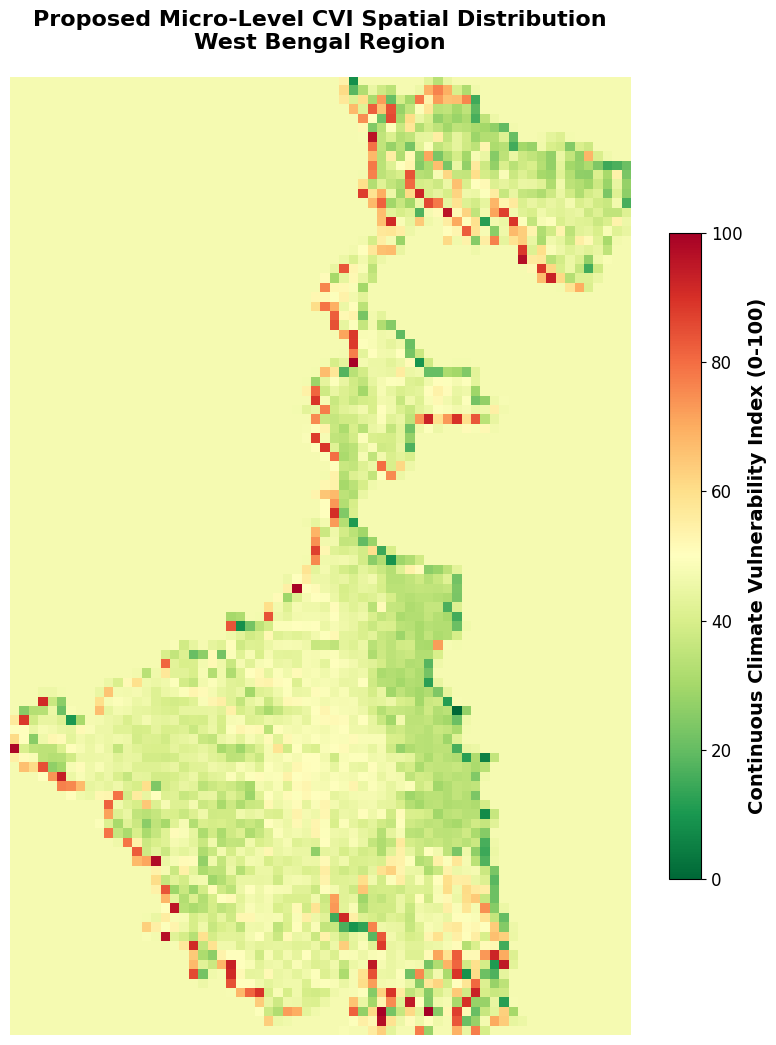

In [11]:
import matplotlib.pyplot as plt

# 1. Retrieve the original grid dimensions from your patch extraction step
# n_patches_y = height // 64
# n_patches_x = width // 64
grid_shape = (n_patches_y, n_patches_x)

print(f"Reshaping 1D scores back to 2D geographic grid: {grid_shape}")

# 2. Reshape the 6,732 continuous scores back into the 2D spatial layout
cvi_map_2d = final_cvi_scores.reshape(grid_shape)

# 3. Generate the Publication-Ready Heatmap
plt.figure(figsize=(10, 14))

# We use the 'RdYlGn_r' (Red-Yellow-Green reversed) colormap.
# This visually enforces that Red = High Vulnerability (100) and Green = Low (0).
plt.imshow(cvi_map_2d, cmap='RdYlGn_r', interpolation='nearest')

# Add academic formatting
cbar = plt.colorbar(shrink=0.6, pad=0.05)
cbar.set_label('Continuous Climate Vulnerability Index (0-100)', fontsize=14, fontweight='bold')
cbar.ax.tick_params(labelsize=12)

plt.title('Proposed Micro-Level CVI Spatial Distribution\nWest Bengal Region',
          fontsize=16, fontweight='bold', pad=20)

# Hide axes to make it look like a pure geographic map
plt.axis('off')

# 4. Save the figure at 300 DPI (Standard requirement for IEEE/Elsevier journals)
plt.savefig('Proposed_CVI_WestBengal_Map.png', dpi=300, bbox_inches='tight')

print("Map generated and saved as 'Proposed_CVI_WestBengal_Map.png' for the manuscript.")
plt.show()